<a href="https://colab.research.google.com/github/Roberto-Raposo/TCC_Treinamento_Garbage_Classification/blob/main/Treinamento_Garbage_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Importação das bibliotecas

import os
import random
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from google.colab import drive
from tensorflow.keras.applications import EfficientNetV2S

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [6]:
# Configurações do projeto

BATCH_SIZE = 16
IMAGE_SIZE = (384, 384)
SEED = 42
NUM_CLASSES = 10
EPOCHS = 20
FINE_TUNE_EPOCHS = 15    # Etapa 2: Fine-Tuning
FINE_TUNE_LR = 1e-5      # LR bem menor para não destruir os pesos do ImageNet
UNFREEZE_FRACTION = 0.3  # descongela os últimos 30% das camadas do modelo base

In [7]:
# Reprodutibilidade

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
# Montagem do Google Drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# Criacao da Estrutura de Diretorios

PROJECT_PATH = "/content/drive/MyDrive/TCC"

folders = [
    "dataset",
    "models",
    "results",
    "graphs",
    "history",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Estrutura criada com sucesso!")

Estrutura criada com sucesso!


In [10]:
# Extracao do Dataset

zip_path = "/content/drive/MyDrive/garbage-classification-v2.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extraído com sucesso!")

✅ Dataset extraído com sucesso!


Analise Exploratoria Do Dataset


In [11]:
# Definicao do Dataset

DATASET_PATH = "/content/dataset/standardized_384"

classes = sorted(os.listdir(DATASET_PATH))

print("Número de classes:", len(classes))
print(classes)

Número de classes: 10
['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [12]:
# Distribuição das imagens por classe (Tabela)

dados = []

for classe in sorted(os.listdir(DATASET_PATH)):
    caminho = os.path.join(DATASET_PATH, classe)

    if os.path.isdir(caminho):
        dados.append({
            "Classe": classe,
            "Quantidade": len(os.listdir(caminho))
        })

df = pd.DataFrame(dados)
df

,Classe,Quantidade
0,battery,756
1,biological,699
2,cardboard,1411
3,clothes,1892
4,glass,1736
5,metal,930
6,paper,1336
7,plastic,1597
8,shoes,1449
9,trash,453


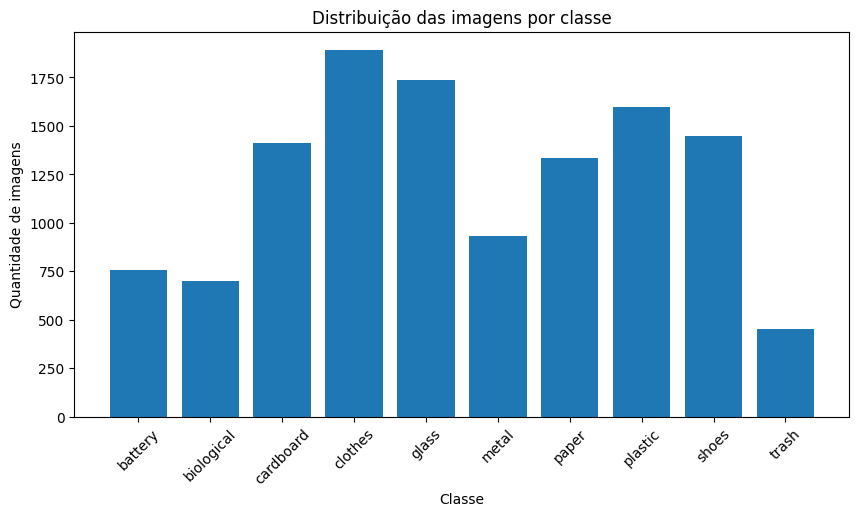

In [13]:
# Distribuição das imagens por classe (Gráfico)

plt.figure(figsize=(10,5))

plt.bar(df["Classe"], df["Quantidade"])

plt.title("Distribuição das imagens por classe")
plt.xlabel("Classe")
plt.ylabel("Quantidade de imagens")

plt.xticks(rotation=45)

# Salva o gráfico na pasta graphs do Google Drive
plt.savefig(
    "/content/drive/MyDrive/TCC/graphs/01_distribuicao_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Verificação de imagens corrompidas

corrompidas = []

for classe in classes:

    pasta = os.path.join(DATASET_PATH, classe)

    for arquivo in os.listdir(pasta):

        caminho = os.path.join(pasta, arquivo)

        try:
            Image.open(caminho).verify()
        except:
            corrompidas.append(caminho)

print("Imagens corrompidas:", len(corrompidas))

Imagens corrompidas: 0


In [15]:
# Análise das dimensões das imagens

larguras = []
alturas = []

for classe in classes:

    pasta = os.path.join(DATASET_PATH, classe)

    for arquivo in os.listdir(pasta):

        img = Image.open(os.path.join(pasta, arquivo))

        largura, altura = img.size

        larguras.append(largura)
        alturas.append(altura)

print("Largura mínima:", min(larguras))
print("Largura máxima:", max(larguras))

print("Altura mínima:", min(alturas))
print("Altura máxima:", max(alturas))

Largura mínima: 384
Largura máxima: 384
Altura mínima: 384
Altura máxima: 384


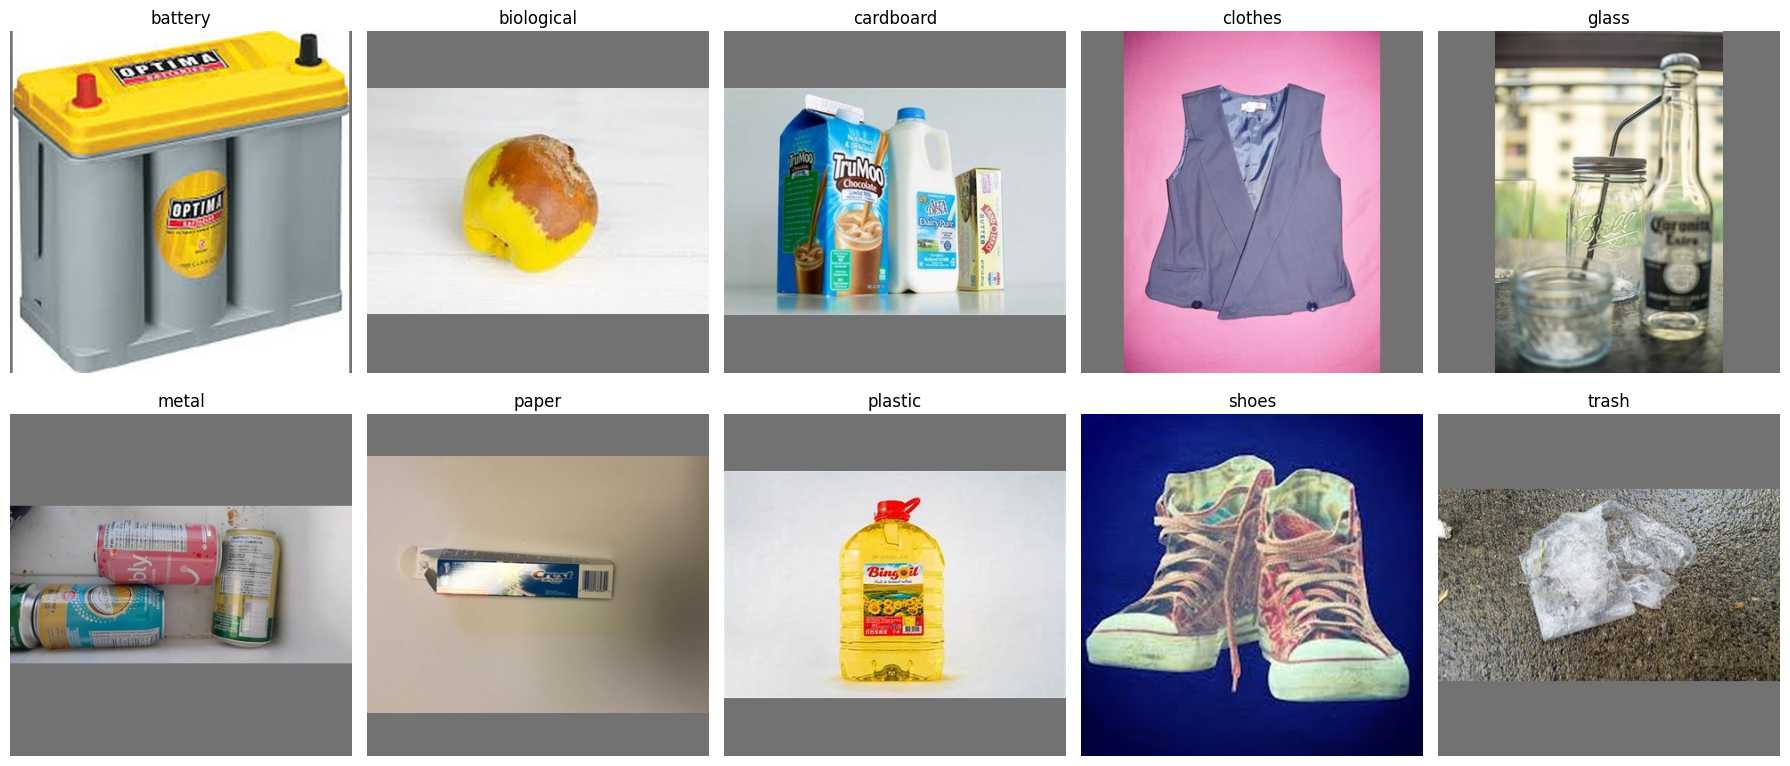

In [16]:
# Visualização de exemplos das classes

plt.figure(figsize=(18,8))

for i, classe in enumerate(classes):

    pasta = os.path.join(DATASET_PATH, classe)

    imagem = random.choice(os.listdir(pasta))

    img = Image.open(os.path.join(pasta, imagem))

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/TCC/graphs/02_exemplos_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Preparacao Dos Dados

In [17]:
# Coleta de caminhos e rotulos de todas as imagens

from sklearn.model_selection import train_test_split
import collections

file_paths = []
labels = []

for idx, classe in enumerate(classes):
    pasta = os.path.join(DATASET_PATH, classe)
    for arquivo in os.listdir(pasta):
        file_paths.append(os.path.join(pasta, arquivo))
        labels.append(idx)

file_paths = np.array(file_paths)
labels = np.array(labels)

print("Total de imagens:", len(file_paths))

Total de imagens: 12259


In [18]:
# Divisao Estratificada em Treino, Validacao e Teste (80% / 10% / 10%)

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths, labels,
    test_size=0.2,
    stratify=labels,
    random_state=SEED
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.5,
    stratify=temp_labels,
    random_state=SEED
)

print("Treino:", len(train_paths))
print("Validação:", len(val_paths))
print("Teste:", len(test_paths))

Treino: 9807
Validação: 1226
Teste: 1226


In [19]:
# Conferencia da distribuicao por classe em cada split

print("Treino:", collections.Counter(train_labels))
print("Validação:", collections.Counter(val_labels))
print("Teste:", collections.Counter(test_labels))

Treino: Counter({np.int64(3): 1513, np.int64(4): 1389, np.int64(7): 1278, np.int64(8): 1159, np.int64(2): 1129, np.int64(6): 1069, np.int64(5): 744, np.int64(0): 605, np.int64(1): 559, np.int64(9): 362})
Validação: Counter({np.int64(3): 190, np.int64(4): 173, np.int64(7): 160, np.int64(8): 145, np.int64(2): 141, np.int64(6): 133, np.int64(5): 93, np.int64(0): 75, np.int64(1): 70, np.int64(9): 46})
Teste: Counter({np.int64(3): 189, np.int64(4): 174, np.int64(7): 159, np.int64(8): 145, np.int64(2): 141, np.int64(6): 134, np.int64(5): 93, np.int64(0): 76, np.int64(1): 70, np.int64(9): 45})


In [20]:
# Calculo dos pesos de classe (class weighting)

from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict = dict(enumerate(class_weights_array))

print("Pesos por classe:")
for idx, peso in class_weight_dict.items():
    print(f"{classes[idx]}: {peso:.3f}")

Pesos por classe:
battery: 1.621
biological: 1.754
cardboard: 0.869
clothes: 0.648
glass: 0.706
metal: 1.318
paper: 0.917
plastic: 0.767
shoes: 0.846
trash: 2.709


In [21]:
# Funcao de carregamento e criacao dos datasets

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMAGE_SIZE)
    image.set_shape([IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def make_dataset(paths, labels, shuffle=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_dataset = make_dataset(train_paths, train_labels, shuffle=True)
validation_dataset = make_dataset(val_paths, val_labels, shuffle=False)
test_dataset = make_dataset(test_paths, test_labels, shuffle=False)

In [22]:
# Validacao dos Batches

print("Batches de treino:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Batches de validação:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Batches de teste:", tf.data.experimental.cardinality(test_dataset).numpy())

Batches de treino: 613
Batches de validação: 77
Batches de teste: 77


In [23]:
# Classes Carregadas

class_names = classes
print(class_names)

['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [24]:
# Formato Dos Dados

for images, labels in train_dataset.take(1):
    print("Formato das imagens:", images.shape)
    print("Formato dos labels:", labels.shape)

Formato das imagens: (16, 384, 384, 3)
Formato dos labels: (16, 10)


Data Augmentation

In [25]:
# Configuração do Data Augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

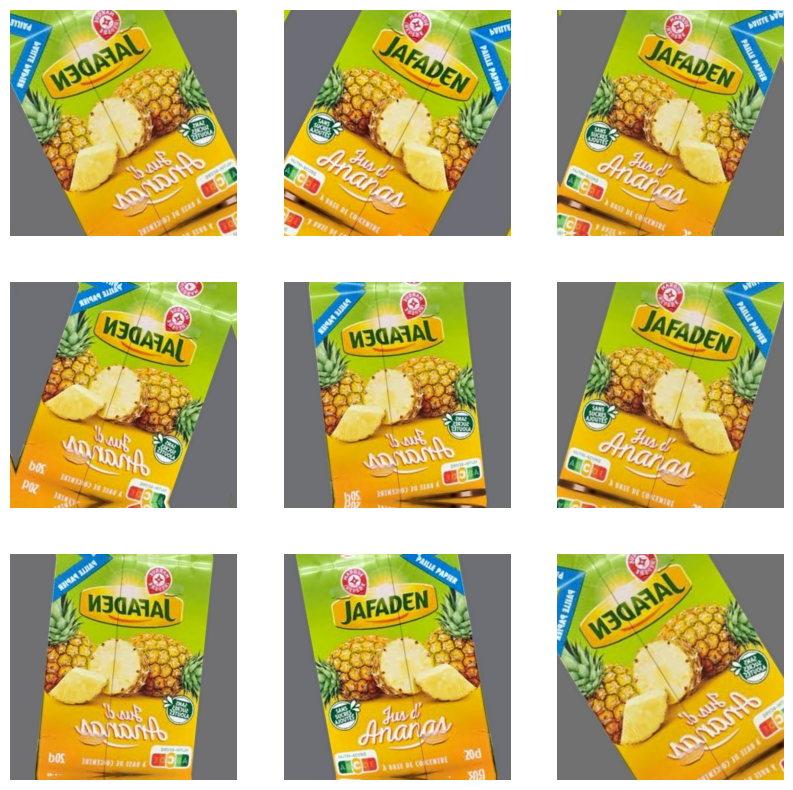

In [26]:
# Visualização das imagens aumentadas

for images, labels in train_dataset.take(1):

    image = images[0]

    plt.figure(figsize=(10,10))

    for i in range(9):
        augmented_image = data_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )

        plt.subplot(3,3,i+1)
        plt.imshow(tf.cast(augmented_image[0], tf.uint8))
        plt.axis("off")

    plt.show()

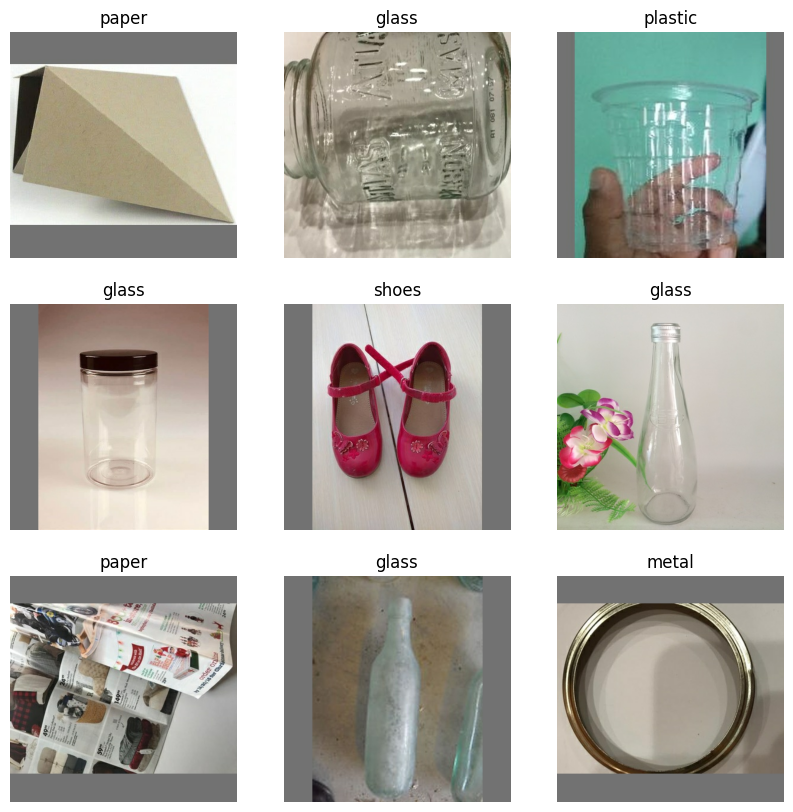

In [27]:
# Visualização das imagens aumentadas

plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")

plt.show()

Otimizacao Do Pipeline

Cosntrucao do Modelo

In [28]:
# Carregamento da EfficientNetV2S

base_model = EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(384, 384, 3)
)

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [29]:
# Congelamento das camadas

base_model.trainable = False

In [30]:
# Construcao da Arquitetura

inputs = keras.Input(shape=(384,384,3))

x = data_augmentation(inputs)   # augmentation: ativo apenas durante o treino

x = base_model(x)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

In [31]:
# Resumo da Arquitetura

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,344,170 (77.61 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

Compilacao do Modelo

In [32]:
# Compilacao

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)

In [33]:
# Conferencia de Compilacao

print(model.loss)

categorical_crossentropy


In [34]:
# Conferencia de Compilacao

print(model.optimizer)

Configuracao dos Callbacks

In [35]:
# EarlyStopping

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [36]:
# ModelCheckpoint

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(PROJECT_PATH, "models", "efficientnetv2s_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [37]:
# ReduceLROnPlateau

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

In [38]:
# Agrupamento dos Callbacks

callbacks = [
    early_stopping,
    checkpoint,
    reduce_lr
]

Treinamento do Modelo

In [39]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.7771 - loss: 0.8757
Epoch 1: val_loss improved from None to 0.25988, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 203s 292ms/step - accuracy: 0.8638 - loss: 0.5341 - val_accuracy: 0.9233 - val_loss: 0.2599 - learning_rate: 0.0010
Epoch 2/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.9070 - loss: 0.2945
Epoch 2: val_loss improved from 0.25988 to 0.22427, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 168s 273ms/step - accuracy: 0.9120 - loss: 0.2781 - val_accuracy: 0.9323 - val_loss: 0.2243 - learning_rate: 0.0010
Epoch 3/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.9214 - loss: 0.2518

In [40]:
# Salvamento do historico

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(PROJECT_PATH, "history", "history_transfer_learning.csv"),
    index=False
)

print("Histórico salvo com sucesso!")

Histórico salvo com sucesso!


Fine-Tuning

In [41]:
# Descongelamento parcial do modelo base (Etapa 2 - Fine-Tuning)

base_model.trainable = True

total_layers = len(base_model.layers)
fine_tune_at = int(total_layers * (1 - UNFREEZE_FRACTION))

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Total de camadas no modelo base: {total_layers}")
print(f"Camadas congeladas: {fine_tune_at}")
print(f"Camadas descongeladas (treináveis): {total_layers - fine_tune_at}")

Total de camadas no modelo base: 513
Camadas congeladas: 359
Camadas descongeladas (treináveis): 154


In [42]:
# Recompilacao do modelo para Fine-Tuning

fine_tune_optimizer = tf.keras.optimizers.Adam(learning_rate=FINE_TUNE_LR)

model.compile(
    optimizer=fine_tune_optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo recompilado com learning rate:", FINE_TUNE_LR)

Modelo recompilado com learning rate: 1e-05


In [43]:
# Callbacks para o Fine-Tuning

early_stopping_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint_ft = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(PROJECT_PATH, "models", "efficientnetv2s_finetuned_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr_ft = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

callbacks_ft = [
    early_stopping_ft,
    checkpoint_ft,
    reduce_lr_ft
]

In [44]:
# Treinamento - Etapa 2 (Fine-Tuning)

history_finetune = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks_ft,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step - accuracy: 0.8581 - loss: 0.4081
Epoch 1: val_loss improved from None to 0.22360, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_finetuned_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 295s 419ms/step - accuracy: 0.8734 - loss: 0.3610 - val_accuracy: 0.9323 - val_loss: 0.2236 - learning_rate: 1.0000e-05
Epoch 2/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step - accuracy: 0.9111 - loss: 0.2532
Epoch 2: val_loss improved from 0.22360 to 0.19222, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_finetuned_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 238s 388ms/step - accuracy: 0.9149 - loss: 0.2470 - val_accuracy: 0.9380 - val_loss: 0.1922 - learning_rate: 1.0000e-05
Epoch 3/15
613/613 ━━━━━━━━━━━━━━━━━━━━

In [45]:
# Salvamento do historico do Fine-Tuning

history_finetune_df = pd.DataFrame(history_finetune.history)

history_finetune_df.to_csv(
    os.path.join(PROJECT_PATH, "history", "history_finetuning.csv"),
    index=False
)

print("Histórico do Fine-Tuning salvo com sucesso!")

Histórico do Fine-Tuning salvo com sucesso!


Avaliacao do Modelo

In [46]:
# Avaliacao do Conjunto de teste

test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Loss no conjunto de teste: {test_loss:.4f}")
print(f"Acurácia no conjunto de teste: {test_accuracy:.4f}")

77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 226ms/step - accuracy: 0.9657 - loss: 0.1072
Loss no conjunto de teste: 0.1072
Acurácia no conjunto de teste: 0.9657


In [47]:
# Geracao das Predicoes

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model(images, training=False)

    true_classes = tf.argmax(labels, axis=1)
    predicted_classes = tf.argmax(predictions, axis=1)

    y_true.extend(true_classes.numpy().tolist())
    y_pred.extend(predicted_classes.numpy().tolist())

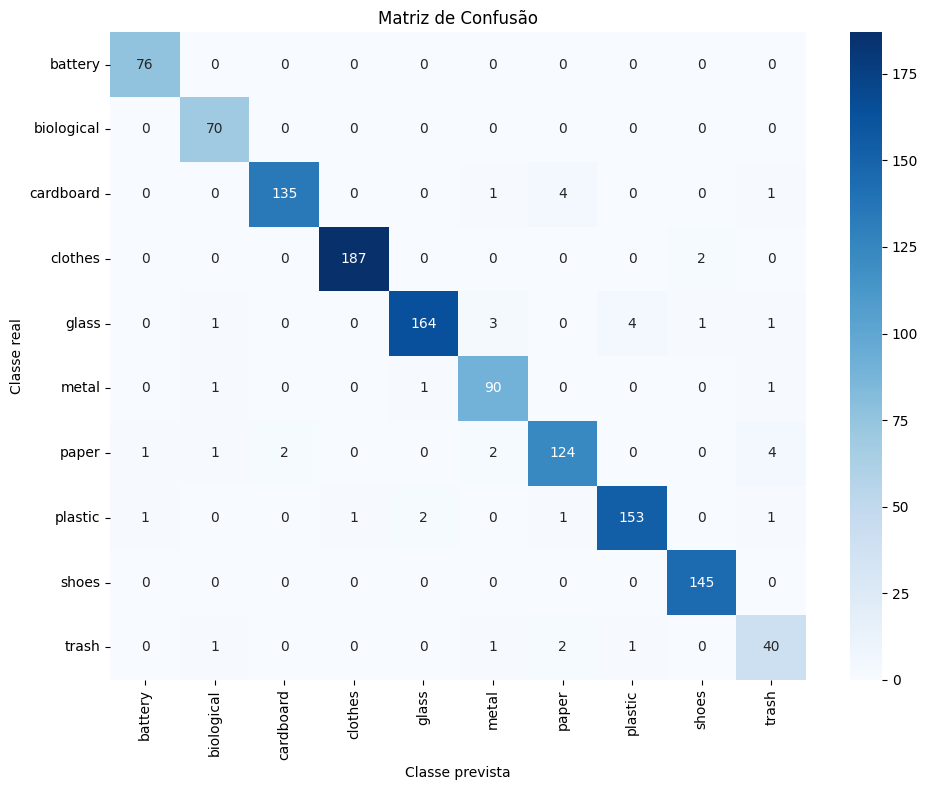

In [48]:
# Matriz de confusao

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de Confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "graphs", "03_matriz_confusao.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
# Classification Report

from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     battery       0.97      1.00      0.99        76
  biological       0.95      1.00      0.97        70
   cardboard       0.99      0.96      0.97       141
     clothes       0.99      0.99      0.99       189
       glass       0.98      0.94      0.96       174
       metal       0.93      0.97      0.95        93
       paper       0.95      0.93      0.94       134
     plastic       0.97      0.96      0.97       159
       shoes       0.98      1.00      0.99       145
       trash       0.83      0.89      0.86        45

    accuracy                           0.97      1226
   macro avg       0.95      0.96      0.96      1226
weighted avg       0.97      0.97      0.97      1226



In [50]:
# Salvamento do Relatorio

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    os.path.join(PROJECT_PATH, "results", "classification_report.csv")
)

report_df

,precision,recall,f1-score,support
battery,0.974359,1.000000,0.987013,76.000000
biological,0.945946,1.000000,0.972222,70.000000
cardboard,0.985401,0.957447,0.971223,141.000000
clothes,0.994681,0.989418,0.992042,189.000000
glass,0.982036,0.942529,0.961877,174.000000
metal,0.927835,0.967742,0.947368,93.000000
paper,0.946565,0.925373,0.935849,134.000000
plastic,0.968354,0.962264,0.965300,159.000000
shoes,0.979730,1.000000,0.989761,145.000000
trash,0.833333,0.888889,0.860215,45.000000


In [51]:
import numpy as np

print("Quantidade de amostras:", len(y_true))
print("Classes presentes em y_true:", np.unique(y_true))
print("Contagem por classe:")

for classe, quantidade in zip(*np.unique(y_true, return_counts=True)):
    print(f"{class_names[classe]}: {quantidade}")

Quantidade de amostras: 1226
Classes presentes em y_true: [0 1 2 3 4 5 6 7 8 9]
Contagem por classe:
battery: 76
biological: 70
cardboard: 141
clothes: 189
glass: 174
metal: 93
paper: 134
plastic: 159
shoes: 145
trash: 45
